# EEG foundation models: an eyes-open / eyes-closed experiment

**Question:** Can frozen pretrained EEG features support a small classifier on held-out participants?

We compare frequency bandpower, CBraMod, and LaBraM using identical participants, windows, and classifier selection. Randomly initialized backbones help distinguish pretraining from architecture. This is a learning project, not a replication of either paper.

**Execution status:** The original experiment and cross-validation completed in the user's Colab session. Reported summaries are in `results/`. This consolidated notebook has no execution outputs and was not rerun on real EEG in the packaging environment.

**Read before interpreting:** LaBraM's paper explicitly includes EEG Motor Movement/Imagery in pretraining (Appendix D). Holding people out of our supervised classifier does not establish that the pretrained encoder never saw them. This dataset supports a tutorial, not an unbiased test of completely unseen-data transfer. CBraMod reports pretraining on TUEG. The models also differ in their pretraining corpora and objectives; a score difference cannot isolate attention design.


## 1. Run locally or in Colab

Local: use Python 3.11, install `requirements.txt`, and open this notebook from this folder.

Colab: upload `eeg_lab.py` and `smoke_test.py` alongside this notebook. Run the following cell in a fresh runtime. Colab supplies PyTorch; keep its compatible torch/torchvision pair. If changing installed NumPy, restart the runtime before importing packages. GPU is helpful for feature extraction, and CPU is supported with small batches.


In [1]:
# Colab only. Keep its existing torch/torchvision, NumPy and SciPy installations.
# Uncomment and run before imports; restart if Colab requests it.
# %pip install 'mne==1.8.0' 'timm==0.9.16' 'einops==0.8.0'
%pip install -r requirements.txt

Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 14.0 MB 5.4 MB/s eta 0:00:01    |███████████████████▋            | 8.6 MB 5.4 MB/s eta 0:00:02
     |████████████████████████████████| 30.3 MB 41.4 MB/s eta 0:00:01     |█████████████████▌              | 16.6 MB 41.4 MB/s eta 0:00:01
     |████████████████████████████████| 11.0 MB 41.1 MB/s eta 0:00:01
     |████████████████████████████████| 7.4 MB 80.3 MB/s eta 0:00:01
     |████████████████████████████████| 7.8 MB 25.1 MB/s eta 0:00:01
     |████████████████████████████████| 63.9 MB 14.2 MB/s eta 0:00:01
     |████████████████████████████████| 1.8 MB 19.0 MB/s eta 0:00:01
     |████████████████████████████████| 2.2 MB 29.8 MB/s eta 0:00:01
     |████████████████████████████████| 43 kB 7.8 MB/s  eta 0:00:01
     |████████████████████████████████| 11.6 MB 44.0 MB/s eta 0:00:01
     |████████████████████████████████| 309 kB 33.3 MB/s eta 0:00:01
     |███████████████████

In [2]:
from pathlib import Path
import json
import platform
import importlib.metadata
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch
import eeg_lab as lab

print('Python:', platform.python_version())
versions = {p: importlib.metadata.version(p) for p in
            ['numpy','scipy','scikit-learn','mne','torch','torchvision','timm','einops']}
print(versions)
(lab.ROOT / 'environment.json').write_text(json.dumps(versions, indent=2))


Python: 3.9.6
{'numpy': '1.26.4', 'scipy': '1.13.1', 'scikit-learn': '1.5.2', 'mne': '1.8.0', 'torch': '2.5.1', 'torchvision': '0.20.1', 'timm': '0.9.16', 'einops': '0.8.0'}


177

## 2. Download the official assets

The helper downloads pinned source snapshots, their licenses, and the released weights. It records weight SHA256 hashes. It uses the original model implementations rather than reproducing an approximation. Expect roughly 120 MB of checkpoint downloads, plus EEG recordings later.

CBraMod produces one embedding per channel and time patch; we average these. For LaBraM we retain its pretrained final token normalization and average patch embeddings, excluding CLS. No randomly initialized task head is used for feature extraction. Strict checkpoint loading rejects incompatible weights instead of silently leaving backbone parameters untrained.

Official sources: [CBraMod](https://github.com/wjq-learning/CBraMod), [LaBraM](https://github.com/935963004/LaBraM), [CBraMod weights](https://huggingface.co/weighting666/CBraMod). Retain upstream code and checkpoint license notices if redistributing.


In [3]:
lab.setup_assets()
print((lab.ROOT / 'asset_manifest.json').read_text())


Sources and weights ready. Revisions and weight hashes: asset_manifest.json
{
  "cbramod_source_revision": "b9e961003214326972c567eff390e75b0287e32a",
  "labram_source_revision": "c431221e6cfd23dbfa9950e0180682fb322b0548",
  "cbramod_checkpoint_revision": "500543c",
  "cbramod.pth_sha256": "0792cb808c14e6b7a2bb2ce1dff379bc47bc54c49a779825bdfeb33bf8157178",
  "labram-base.pth_sha256": "7c50583826afac76c4ab18f43d958df40496c8229accc09ed6a227c9bb57c37c"
}


## 3. Prepare public EEG

[PhysioNet EEG Motor Movement/Imagery](https://physionet.org/content/eegmmidb/1.0.0/) includes baseline runs: **run 1 = eyes open (0), run 2 = eyes closed (1)**. We use subjects 1–20 and these two runs only. The dataset is available without an application; follow its attribution license and cite its creators.

The original sample rate is 160 Hz. Our pipeline standardizes channel labels, selects 19 channels, uses an average reference, filters 1–40 Hz, resamples to 200 Hz, trims recording edges, and takes non-overlapping four-second windows. A fixed amplitude threshold rejects extreme windows. Inspect the retained counts; this threshold is deliberately simple, not comprehensive artifact removal.

**Unit check:** MNE returns volts. Divide by `1e-4 V` to express signal values in units of 100 microvolts. Do not silently pass volts or per-window standardized values to the checkpoints.

The chosen downstream filter differs from both papers' pretraining filters. We use it consistently across all methods and document that choice. Resampling does not create additional measured bandwidth.


In [4]:
data = lab.load_public_data(subjects=range(1,21))
X, y, subjects = data['X'], data['y'], data['subjects']
print('EEG:', X.shape, 'labels:', np.bincount(y))
print('Max absolute amplitude (100 microvolt units):', np.max(np.abs(X)))
print('Channel order:', list(data['channels']))
counts = json.loads((lab.ROOT / 'data_counts.json').read_text())
for row in counts:
    print(row)


/Users/anirudhsekar/Library/Python/3.9/lib/python/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/anirudhsekar/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


EEG: (542, 19, 800) labels: [262 280]
Max absolute amplitude (100 microvolt units): 4.992964
Channel order: ['Fp1', 'Fp2', 'F7', 'F3', 'Fz', 'F4', 'F8', 'T7', 'C3', 'Cz', 'C4', 'T8', 'P7', 'P3', 'Pz', 'P4', 'P8', 'O1', 'O2']
{'subject': 1, 'run': 1, 'label': 0, 'windows': 14}
{'subject': 1, 'run': 2, 'label': 1, 'windows': 14}
{'subject': 2, 'run': 1, 'label': 0, 'windows': 14}
{'subject': 2, 'run': 2, 'label': 1, 'windows': 14}
{'subject': 3, 'run': 1, 'label': 0, 'windows': 8}
{'subject': 3, 'run': 2, 'label': 1, 'windows': 14}
{'subject': 4, 'run': 1, 'label': 0, 'windows': 14}
{'subject': 4, 'run': 2, 'label': 1, 'windows': 14}
{'subject': 5, 'run': 1, 'label': 0, 'windows': 14}
{'subject': 5, 'run': 2, 'label': 1, 'windows': 14}
{'subject': 6, 'run': 1, 'label': 0, 'windows': 14}
{'subject': 6, 'run': 2, 'label': 1, 'windows': 14}
{'subject': 7, 'run': 1, 'label': 0, 'windows': 14}
{'subject': 7, 'run': 2, 'label': 1, 'windows': 14}
{'subject': 8, 'run': 1, 'label': 0, 'windows': 

## 4. Trace every tensor

A batch is `(B,19,800)` after preprocessing. Four seconds at 200 Hz gives 800 samples per channel. Each channel becomes four one-second patches, giving `(B,19,4,200)`: **76 EEG patches per example**. The last 200 denotes measured sample values here; the models also happen to use a 200-dimensional hidden representation. These two meanings are distinct.

A channel measures a voltage difference. Changing its reference changes its signal, even if the electrode name stays the same. Preserve reference choice and channel ordering when running comparisons.


In [5]:
patches = lab.patchify(X[:2])
print('Raw batch:', X[:2].shape)
print('Patched batch:', patches.shape)
assert patches.shape == (2,19,4,200)
np.testing.assert_array_equal(patches.reshape(2,19,800), X[:2])


Raw batch: (2, 19, 800)
Patched batch: (2, 19, 4, 200)


## 5. Inspect a plausible signal before training

Our hypothesis is that posterior alpha-band power will help separate conditions. Check the data rather than assuming the hypothesis holds for every participant. Use only training participants for exploratory design choices; keep test participants untouched until the final evaluation.


{'train': [16, 10, 15, 8, 13, 11, 7, 20, 4, 1, 17, 6], 'validation': [12, 19, 3, 5], 'test': [18, 2, 14, 9]}


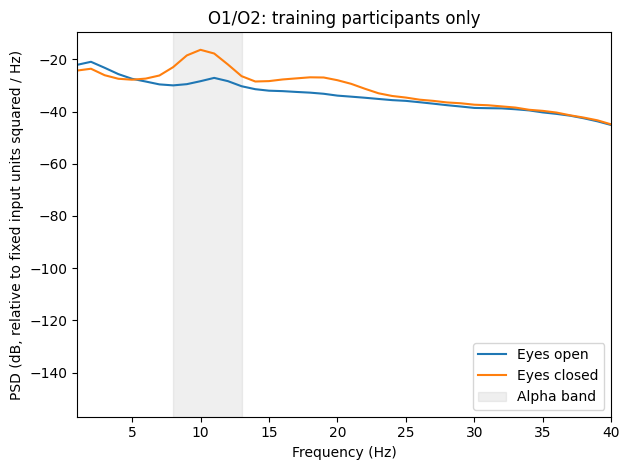

In [6]:
masks, ids = lab.split_subjects(subjects)
train, validation, test = masks
print(dict(zip(['train','validation','test'], [p.tolist() for p in ids])))
frequencies, psd = welch(X[train,-2:,:], fs=200, nperseg=200, axis=-1)
for label, name in [(0,'Eyes open'),(1,'Eyes closed')]:
    mean_psd = psd[y[train] == label].mean(axis=(0,1))
    plt.plot(frequencies, 10*np.log10(np.maximum(mean_psd,1e-20)), label=name)
plt.axvspan(8,13,alpha=.12,color='gray',label='Alpha band')
plt.xlim(1,40)
plt.xlabel('Frequency (Hz)')
plt.ylabel('PSD (dB, relative to fixed input units squared / Hz)')
plt.title('O1/O2: training participants only')
plt.legend()
plt.tight_layout()
plt.show()


## 6. Establish the inexpensive baseline

Extract five log bandpowers per channel: delta, theta, alpha, beta, and 30–40 Hz. That gives 95 features. Fit a scaler and logistic regression on training participants only; choose its regularization using validation participants only.

Balanced accuracy averages the two class recalls; its chance reference is 0.5. Macro F1 weights classes equally. AUROC tests how well continuous scores rank the labels. The confusion matrix uses rows=true and columns=predicted, in `[open, closed]` order.


In [7]:
baseline = lab.evaluate(lab.bandpower_features(X), y, subjects, masks)
print(json.dumps(baseline, indent=2))


{
  "validation_balanced_accuracy": 0.9285714285714286,
  "selected_C": 1.0,
  "test_balanced_accuracy": 0.7130102040816326,
  "test_macro_f1": 0.7130102040816326,
  "test_auroc": 0.7580174927113702,
  "confusion_matrix": [
    [
      34,
      15
    ],
    [
      15,
      41
    ]
  ],
  "per_subject_balanced_accuracy": {
    "2": 0.8928571428571428,
    "9": 0.5,
    "14": 0.5357142857142857,
    "18": 1.0
  }
}


## 7. Evaluate both frozen backbones and their random controls

This is a **linear probe**: the encoder's parameters stay frozen while the classifier learns from labels. Full fine-tuning would also update encoder parameters. Start here because it directly asks whether the existing representations expose useful information.

The next cell extracts features for both pretrained encoders and random counterparts. With a GPU, batch size 8 is a conservative default. CPU execution can take substantially longer; for an initial plumbing check, prepare five subjects in a separate run, then rerun the planned twenty-person experiment from scratch. Never compare methods across different splits.

A single label-control run flips the open/closed mapping independently for each subject and preserves entire recording groups. It should disrupt a consistent class relationship across people, but with few held-out people it may deviate substantially from chance. It is a sanity check, not a statistical significance test.


In [8]:
# Resume completed feature extractions if the data and its row order are unchanged.
results = lab.run_experiment(data, include_models=False)
for kind in ['cbramod', 'labram']:
    for pretrained in [True, False]:
        name = f"{kind}_{'pretrained' if pretrained else 'random'}"
        path = lab.ROOT / f'{name}_features.npy'
        if path.exists():
            print('Reusing saved features:', name, flush=True)
            features = np.load(path, allow_pickle=False)
        else:
            print('Extracting:', name, flush=True)
            features = lab.extract_features(X, kind, pretrained)
            np.save(path, features)
        assert features.shape == (len(X), 200)
        results['methods'][name] = lab.evaluate(features, y, subjects, masks)
        (lab.ROOT / 'results.json').write_text(json.dumps(results, indent=2))
print(json.dumps(results, indent=2))


Extracting: cbramod_pretrained
Extracting: cbramod_random
Extracting: labram_pretrained
Extracting: labram_random
{
  "split": {
    "train": [
      16,
      10,
      15,
      8,
      13,
      11,
      7,
      20,
      4,
      1,
      17,
      6
    ],
    "validation": [
      12,
      19,
      3,
      5
    ],
    "test": [
      18,
      2,
      14,
      9
    ]
  },
  "note": "Frozen representations plus validation-selected logistic regression; not paper replication.",
  "pretraining_overlap": "LaBraM Appendix D includes this PhysioNet corpus. Supervised subject isolation does not establish unseen-pretraining-data transfer.",
  "methods": {
    "bandpower": {
      "validation_balanced_accuracy": 0.9285714285714286,
      "selected_C": 1.0,
      "test_balanced_accuracy": 0.7130102040816326,
      "test_macro_f1": 0.7130102040816326,
      "test_auroc": 0.7580174927113702,
      "confusion_matrix": [
        [
          34,
          15
        ],
        [
      

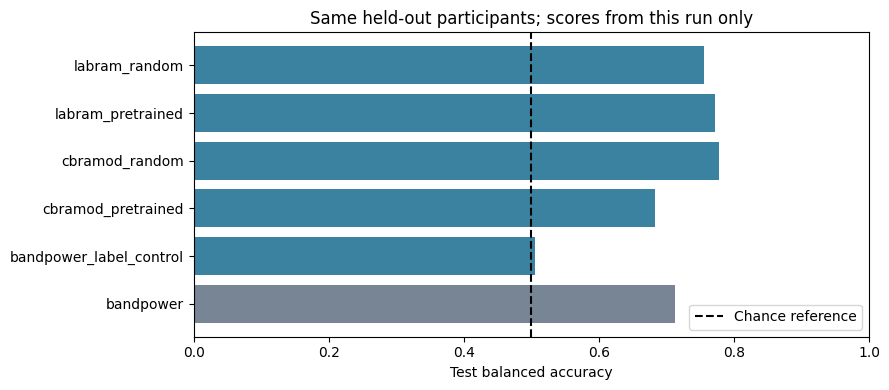

In [9]:
methods = results['methods']
names = list(methods)
values = [methods[n]['test_balanced_accuracy'] for n in names]
plt.figure(figsize=(9,4))
plt.barh(names,values,color=['#788595'] + ['#3b82a0']*(len(names)-1))
plt.axvline(.5,color='black',linestyle='--',label='Chance reference')
plt.xlim(0,1)
plt.xlabel('Test balanced accuracy')
plt.title('Same held-out participants; scores from this run only')
plt.legend()
plt.tight_layout()
plt.savefig(lab.ROOT / 'comparison.png', dpi=160)
plt.show()


## Repeated nested participant cross-validation

The initial split can be sensitive to which four people were held out. This addition reuses existing features and evaluates all twenty people with three repetitions of five outer folds. Four inner participant folds select classifier regularization using only outer-training participants. Feature scaling is fitted inside each training fold. No encoder parameters are updated.

The summary weights participants equally. AUROC is calculated within each participant, then averaged, so it differs from the initial pooled-window AUROC. Repetition SD is descriptive and is not a confidence interval. LaBraM's pretraining overlap remains, and this is a follow-up analysis after inspection of an initial split. Upload `eeg_cross_validation.py` beside the other helper files in Colab.


Using cached encoder features. No GPU work or downloads.
This is a follow-up analysis of the same twenty people; pretraining overlap still applies.
Repeat 1/3, fold 1/5: bandpower
Repeat 1/3, fold 1/5: cbramod_pretrained
Repeat 1/3, fold 1/5: cbramod_random
Repeat 1/3, fold 1/5: labram_pretrained
Repeat 1/3, fold 1/5: labram_random
Repeat 1/3, fold 1/5: bandpower_label_control
Repeat 1/3, fold 2/5: bandpower
Repeat 1/3, fold 2/5: cbramod_pretrained
Repeat 1/3, fold 2/5: cbramod_random
Repeat 1/3, fold 2/5: labram_pretrained
Repeat 1/3, fold 2/5: labram_random
Repeat 1/3, fold 2/5: bandpower_label_control
Repeat 1/3, fold 3/5: bandpower
Repeat 1/3, fold 3/5: cbramod_pretrained
Repeat 1/3, fold 3/5: cbramod_random
Repeat 1/3, fold 3/5: labram_pretrained
Repeat 1/3, fold 3/5: labram_random
Repeat 1/3, fold 3/5: bandpower_label_control
Repeat 1/3, fold 4/5: bandpower
Repeat 1/3, fold 4/5: cbramod_pretrained
Repeat 1/3, fold 4/5: cbramod_random
Repeat 1/3, fold 4/5: labram_pretrained
Repeat

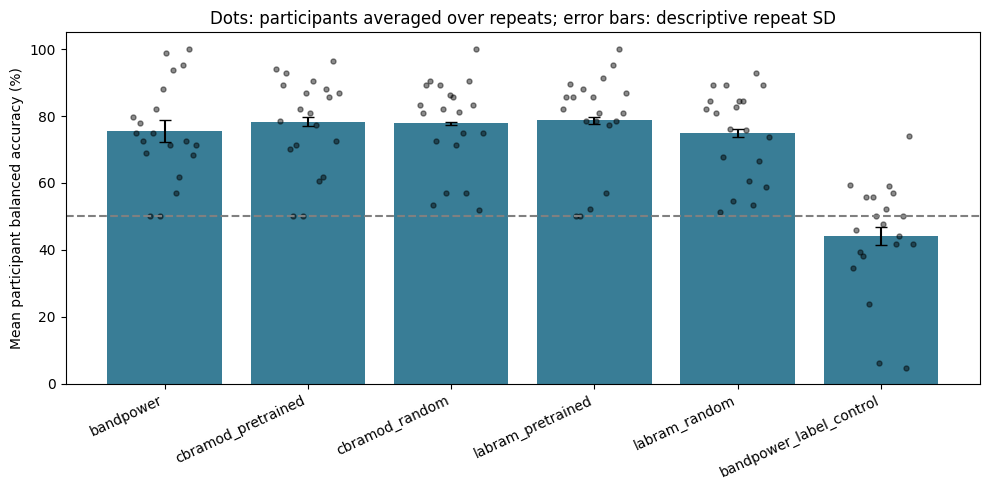

In [10]:
from eeg_cross_validation import run_cached_cv
cv_results = run_cached_cv(
    data, root=lab.ROOT, repeats=3, outer_folds=5, inner_folds=4, seed=42
)
